# 03 · Preparación de los datos para la modelización

**Objetivo:** convertir el dataset del notebook 01 en los conjuntos con los que se entrenarán y evaluarán los modelos, aplicando las decisiones que salieron del análisis exploratorio (notebook 02):

1. Expresar todos los salarios en **euros de 2022** (deflactar con el IPC).
2. Elegir las **variables de entrada**, descartando las que no se pueden usar.
3. Revisar la **coherencia** de las horas de trabajo.
4. Tratar los **casos especiales**: tamaños de empresa sin desagregar y salarios extremos.
5. Definir la **variable objetivo**: el logaritmo del salario.
6. Separar **entrenamiento y prueba** sin que una misma empresa aparezca en ambos.

Toda la lógica está en `src/preparacion.py`, porque la API la reutilizará para transformar los datos que introduzca el usuario exactamente igual que en el entrenamiento. El notebook muestra y justifica cada paso.

Fuente: INE, www.ine.es.

### Preparación del entorno

Funciona tanto en local (abriendo el notebook dentro del repositorio clonado) como en **Google Colab**: si se abre en Colab sin el repositorio, lo descarga de GitHub automáticamente y, si hacen falta, pide subir los microdatos del INE.

In [1]:
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/alfredobrocalserrano/tfm-salarios-ees"
EN_COLAB = "google.colab" in sys.modules


def buscar_raiz():
    """Devuelve la carpeta del proyecto (la que contiene src/) o None si no está."""
    for carpeta in [Path.cwd(), *Path.cwd().parents]:
        if (carpeta / "src").is_dir():
            return carpeta
    return None


RAIZ = buscar_raiz()
if RAIZ is None:
    if EN_COLAB:
        RAIZ = Path("/content/tfm-salarios-ees")
        if not RAIZ.exists():
            print("Descargando el repositorio del proyecto...")
            subprocess.run(["git", "clone", "-q", REPO_URL, str(RAIZ)], check=True)
    else:
        raise FileNotFoundError(
            "No se encuentra la carpeta src/ del proyecto. Clona el repositorio "
            f"({REPO_URL}) y abre el notebook desde dentro (ver README)."
        )

sys.path.insert(0, str(RAIZ))
print("Carpeta del proyecto:", RAIZ)

Carpeta del proyecto: /home/claude/tfm-salarios-ees


In [2]:
# Solo en Colab: si no está el dataset procesado ni los microdatos del INE, se piden para subirlos
if EN_COLAB and not (RAIZ / "data" / "processed" / "ees_2018_2022.parquet").exists():
    from google.colab import files

    carpeta_raw = RAIZ / "data" / "raw"
    carpeta_raw.mkdir(parents=True, exist_ok=True)
    faltan = [a for a in (2018, 2022) if not (carpeta_raw / f"md_EES_{a}.parquet").exists()]
    if faltan:
        print("Sube los ficheros:", ", ".join(f"md_EES_{a}.parquet" for a in faltan))
        for nombre, contenido in files.upload().items():
            for anio in faltan:
                if str(anio) in nombre and nombre.endswith(".parquet"):
                    (carpeta_raw / f"md_EES_{anio}.parquet").write_bytes(contenido)
                    print("Guardado:", f"md_EES_{anio}.parquet")

In [3]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import skew

from src.datos import cargar_dataset_procesado
from src.estadistica import cuantil_ponderado, mediana_ponderada
from src import preparacion as prep

pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid", font_scale=0.95)
EUROS = mticker.FuncFormatter(lambda x, _: f"{x:,.0f} €".replace(",", "."))
AZUL, ROJO = "#3B6EA5", "#C0392B"

ees = cargar_dataset_procesado()
print(f"Registros de partida: {len(ees):,}")

Registros de partida: 457,216


## 1. Salarios en euros de 2022

Para comparar 2018 con 2022, y para entrenar o validar con ambos años, los salarios deben estar en la misma moneda. Se multiplica el salario de 2018 por la variación del **IPC general (media anual, base 2021)** publicado por el INE.

In [4]:
ipc = pd.Series(prep.IPC_MEDIA_ANUAL, name="IPC (media anual, base 2021)")
factor_2018 = prep.IPC_MEDIA_ANUAL[2022] / prep.IPC_MEDIA_ANUAL[2018]
print(ipc.to_string())
print(f"\nFactor 2018 → euros de 2022: {factor_2018:.4f} (inflación acumulada del {100 * (factor_2018 - 1):.1f} %)")

2018     96.6
2019     97.3
2020     97.0
2021    100.0
2022    108.4

Factor 2018 → euros de 2022: 1.1222 (inflación acumulada del 12.2 %)


In [5]:
ees = prep.deflactar(prep.construir_variables(ees))

pd.DataFrame({
    anio: {
        "Mediana nominal (€)": mediana_ponderada(g["salario_anual"], g["FACTOTAL"]),
        "Mediana en euros de 2022 (€)": mediana_ponderada(g["salario_real"], g["FACTOTAL"]),
        "P10 en euros de 2022 (€)": cuantil_ponderado(g["salario_real"], g["FACTOTAL"], 0.10),
        "P90 en euros de 2022 (€)": cuantil_ponderado(g["salario_real"], g["FACTOTAL"], 0.90),
    }
    for anio, g in ees.groupby("anio")
}).round(0)

,2018,2022
Mediana nominal (€),20076.0,22381.0
Mediana en euros de 2022 (€),22529.0,22381.0
P10 en euros de 2022 (€),9489.0,10657.0
P90 en euros de 2022 (€),48676.0,48212.0


Una vez descontada la inflación, **la mediana de 2022 es prácticamente igual que la de 2018**: la subida nominal del 11 % se la llevó el IPC. Los que sí ganaron poder adquisitivo son los salarios bajos (el P10 sube un 12 % real, por el SMI), mientras que el P90 pierde un 1 %.

## 2. Variables de entrada

El fichero tiene 56 columnas, pero no todas pueden usarse para predecir el salario:

- **Componentes del propio salario** (salario base, complementos, pagas extra, horas extraordinarias, retenciones de IRPF, cotizaciones...). Son parte de lo que se quiere predecir: usarlas sería hacer trampa (*fuga de información* o *data leakage*).
- **Detalles que nadie conoce de memoria ni tienen sentido para predecir** (días de vacaciones, puentes, días en situaciones especiales, meses como fijo discontinuo...).
- **Identificadores y pesos** (empresa, número de trabajador, factor de elevación), que se usan para otras cosas, pero no como variables de entrada.

Las variables elegidas describen **el puesto, la persona y la empresa**, y casi todas las puede responder cualquier trabajador:

In [6]:
descripcion = {
    "ocupacion": "Grupo de ocupación (17 grupos CNO-11)",
    "sector": "Sector de actividad de la empresa (27 grupos CNAE-09)",
    "estudios": "Nivel de estudios terminados (7 niveles)",
    "region": "Región (7 zonas NUTS-1)",
    "edad": "Tramo de edad (6 tramos)",
    "sexo": "Sexo",
    "nacionalidad": "España / resto del mundo",
    "jornada": "Tiempo completo / parcial",
    "contrato": "Indefinido / temporal",
    "tamano_empresa": "Tamaño del centro de trabajo (3 tramos)",
    "control": "Empresa pública o privada",
    "responsabilidad": "Tiene tareas de organización o supervisión",
    "convenio": "Tipo de convenio colectivo",
    "mercado": "Mercado principal de la empresa (local, nacional, UE, mundial)",
    "horas_semanales": "Horas semanales pactadas (numérica)",
    "antiguedad": "Años en la empresa (numérica)",
}
pd.DataFrame({
    "descripcion": descripcion,
    "tipo": {v: ("numérica" if v in prep.VARIABLES_NUMERICAS else "categórica") for v in descripcion},
    "en la web": {v: ("sí" if v in prep.VARIABLES_APP else "no") for v in descripcion},
})

,descripcion,tipo,en la web
ocupacion,Grupo de ocupación (17 grupos CNO-11),categórica,sí
sector,Sector de actividad de la empresa (27 grupos C...,categórica,sí
estudios,Nivel de estudios terminados (7 niveles),categórica,sí
region,Región (7 zonas NUTS-1),categórica,sí
edad,Tramo de edad (6 tramos),categórica,sí
sexo,Sexo,categórica,sí
nacionalidad,España / resto del mundo,categórica,sí
jornada,Tiempo completo / parcial,categórica,sí
contrato,Indefinido / temporal,categórica,sí
tamano_empresa,Tamaño del centro de trabajo (3 tramos),categórica,sí


El **tipo de convenio** y el **mercado principal de la empresa** aportan algo de información (notebook 02), pero un usuario normal no suele saberlos. Por eso se entrenarán **dos versiones del modelo** en el notebook 04: una completa y otra solo con las variables que se piden en la web. Así se podrá medir cuánta precisión se pierde por simplificar el formulario.

## 3. Coherencia de las horas de trabajo

En el notebook 02 se vio que la jornada es la variable que más explica el salario, así que conviene incluir también **cuántas horas** se trabajan. La encuesta tiene dos medidas: horas **semanales** pactadas (`JSP1` + `JSP2`/60) y **anuales** pactadas (`JAP`). Se comprueba que sean coherentes.

In [7]:
e22 = ees[ees["anio"] == 2022]
print(f"Correlación horas semanales - horas anuales: {np.corrcoef(e22['horas_semanales'], e22['JAP'])[0, 1]:.3f}")

(e22.assign(semanas_equivalentes=e22["JAP"] / e22["horas_semanales"])
    .groupby("jornada", observed=True)[["horas_semanales", "JAP", "semanas_equivalentes"]]
    .median().round(1))

Correlación horas semanales - horas anuales: 0.929


,horas_semanales,JAP,semanas_equivalentes
jornada,,,
Tiempo completo,40.0,1752.0,44.2
Tiempo parcial,25.0,1058.0,45.0


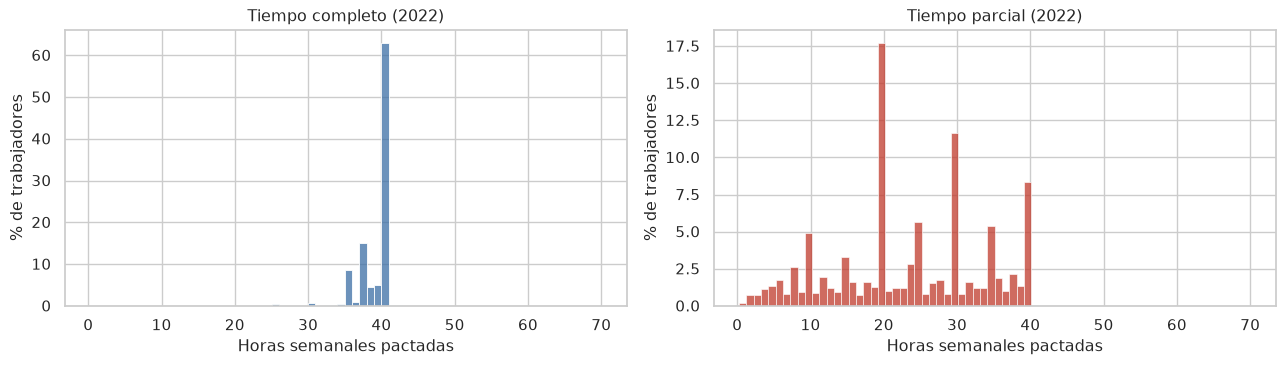

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), sharex=True)
for eje, (jornada, color) in zip(ax, [("Tiempo completo", AZUL), ("Tiempo parcial", ROJO)]):
    sns.histplot(data=e22[e22["jornada"] == jornada], x="horas_semanales", weights="FACTOTAL",
                 binwidth=1, stat="percent", color=color, ax=eje)
    eje.set(title=f"{jornada} (2022)", xlabel="Horas semanales pactadas", ylabel="% de trabajadores")
plt.tight_layout()
plt.show()

Las dos medidas son coherentes: horas anuales ≈ horas semanales × 44–45 semanas, tanto a tiempo completo como a tiempo parcial.

El gráfico muestra además que "tiempo parcial" no siempre significa pocas horas a la semana: los valores más frecuentes son 20 y 30 horas, pero **un 20 % de los contratos a tiempo parcial declara 35 horas o más**. El 60 % de esos casos no trabajó los 12 meses del año, y abundan en hostelería y servicios auxiliares: probablemente son contratos de temporada o fijos discontinuos, parciales en el cómputo anual. Por eso conviene que el modelo reciba **tanto la jornada como las horas semanales**: cada una aporta información que la otra no recoge del todo.

**Decisión:** se usa `horas_semanales`, que contiene la misma información y es la que cualquier persona sabe responder en el formulario de la web.

## 4. Casos especiales

### 4.1 Tamaños de empresa sin desagregar
Como se vio en los notebooks 01 y 02, el INE agrupa algunos tamaños de empresa para proteger el anonimato. Esos registros no corresponden a un tamaño concreto y el usuario de la web nunca los elegiría, así que **se excluyen**.

In [9]:
sin_desagregar = ees["tamano_empresa"].isin(prep.TAMANOS_SIN_DESAGREGAR)
print(f"Registros con tamaño sin desagregar: {sin_desagregar.sum():,} ({100 * sin_desagregar.mean():.1f} %)")
print(f"Mediana de ese grupo: {mediana_ponderada(ees.loc[sin_desagregar, 'salario_real'], ees.loc[sin_desagregar, 'FACTOTAL']):,.0f} € "
      f"(general: {mediana_ponderada(ees['salario_real'], ees['FACTOTAL']):,.0f} €)")

Registros con tamaño sin desagregar: 11,173 (2.4 %)
Mediana de ese grupo: 24,919 € (general: 22,445 €)


Su salario mediano es algo superior al general, pero son solo el 2,4 % de los registros y se reparten entre todas las ocupaciones y sectores, así que excluirlos apenas afecta al conjunto.

### 4.2 Ocupaciones militares
Es el único grupo de ocupación con tan pocos registros que no se puede estimar:

In [10]:
(ees[ees["ocupacion"] == "Ocupaciones militares"]
    .groupby("anio").agg(registros=("IDENCCC", "size"), centros_de_trabajo=("IDENCCC", "nunique")))

,registros,centros_de_trabajo
anio,,
2018,51,2
2022,28,3


Con apenas unas decenas de registros por año, procedentes de muy pocos centros de trabajo, el modelo no puede aprender nada fiable de este grupo: al separar por empresa, casi todos acabarían en el entrenamiento o en la prueba. Además, la encuesta solo cubre a los empleados públicos del Régimen General de la Seguridad Social, así que buena parte del personal militar queda fuera de ella: estos registros no representarían bien a la profesión. **Se excluye del modelo y de la web**, y así se indicará en la página "Cómo funciona".

### 4.3 Salarios extremadamente altos
Al revisar los salarios más altos aparece algo revelador:

In [11]:
for anio, g in ees.groupby("anio"):
    mas_altos = (g["salario_real"].sort_values(ascending=False).head(12) / 1000).round(1).tolist()
    print(f"{anio} - los 12 salarios más altos (miles de €): {mas_altos}")

2018 - los 12 salarios más altos (miles de €): [4742.2, 4741.7, 4741.7, 4741.7, 4741.7, 2557.7, 2460.6, 2460.6, 2460.6, 2460.6, 2460.6, 1854.2]
2022 - los 12 salarios más altos (miles de €): [2794.9, 2793.7, 2793.5, 2792.0, 2779.7, 2555.1, 2549.7, 2540.9, 2538.0, 2532.6, 1792.4, 1223.7]


Los valores más altos aparecen **en bloques de cinco cifras idénticas**. Es la **microagregación** que aplica el INE para anonimizar: sustituye los valores extremos por la media de pequeños grupos, de modo que nadie pueda ser identificado. Esos importes no son salarios individuales reales.

**Decisión:** en lugar de eliminar estos registros, se **limita (recorta)** su salario al **percentil 99,9** de cada año. Así se conserva la información de que son salarios muy altos, sin que unos pocos valores artificiales distorsionen el modelo. Afecta al 0,1 % de los asalariados (en la muestra, a algo más registros, porque los directivos de las grandes empresas tienen pesos pequeños). Los salarios más bajos **no** se recortan: el notebook 02 mostró que son reales (tiempo parcial).

## 5. Aplicación de todos los pasos

In [12]:
datos, registro = prep.preparar(cargar_dataset_procesado())

pd.Series({
    "Registros iniciales": registro["registros_iniciales"],
    "Excluidos (tamaño sin desagregar)": -registro["excluidos_tamano_sin_desagregar"],
    "Excluidos (ocupaciones militares)": -registro["excluidos_ocupaciones_militares"],
    "Registros finales": registro["registros_finales"],
    "Recortados por arriba en 2018": registro["recortados_por_arriba"][2018],
    "Recortados por arriba en 2022": registro["recortados_por_arriba"][2022],
    "Umbral de recorte 2018 (€ de 2022)": registro["umbral_recorte"][2018],
    "Umbral de recorte 2022 (€)": registro["umbral_recorte"][2022],
}).to_frame("valor")

,valor
Registros iniciales,457216.00
Excluidos (tamaño sin desagregar),-11173.00
Excluidos (ocupaciones militares),-79.00
Registros finales,445964.00
Recortados por arriba en 2018,1488.00
Recortados por arriba en 2022,1916.00
Umbral de recorte 2018 (€ de 2022),137459.92
Umbral de recorte 2022 (€),127418.41


## 6. Variable objetivo: el logaritmo del salario

Los modelos se entrenarán para predecir `log(salario)` en lugar del salario directamente, por tres razones:
1. La distribución del salario es muy asimétrica y su logaritmo es casi simétrico (notebook 02).
2. Las diferencias salariales son **proporcionales**: tener estudios superiores no suma una cantidad fija, sino un porcentaje. En escala logarítmica, esos efectos se vuelven aditivos.
3. Un error del 10 % pesa igual en un salario de 15.000 € que en uno de 60.000 €.

Las predicciones se devuelven a euros con la exponencial.

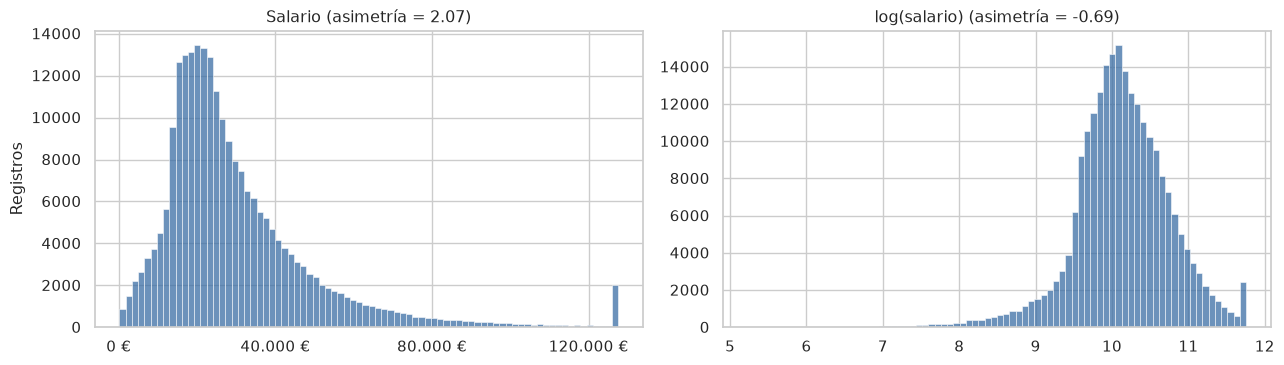

In [13]:
d22 = datos[datos["anio"] == 2022]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
sns.histplot(d22["salario_real"], bins=80, color=AZUL, ax=ax[0])
ax[0].xaxis.set_major_formatter(EUROS)
ax[0].xaxis.set_major_locator(mticker.MultipleLocator(40_000))
ax[0].set(title=f"Salario (asimetría = {skew(d22['salario_real']):.2f})", xlabel="", ylabel="Registros")
sns.histplot(d22[prep.OBJETIVO], bins=80, color=AZUL, ax=ax[1])
ax[1].set(title=f"log(salario) (asimetría = {skew(d22[prep.OBJETIVO]):.2f})", xlabel="", ylabel="")
plt.tight_layout()
plt.show()

El logaritmo reduce la asimetría de 2,1 a −0,7. La cola izquierda que queda corresponde a contratos de muy pocas horas, y la pequeña barra del extremo derecho es el recorte del percentil 99,9 (sección 4.3). Los histogramas cuentan registros sin ponderar: aquí interesa la forma de la variable con la que aprenderá el modelo.

## 7. Entrenamiento y prueba: separación por empresa

Se reserva un **20 % de los datos de 2022 para la prueba final**, que el modelo no verá durante el entrenamiento.

La separación no se hace por trabajadores al azar, sino **por empresas** (`IDENCCC`): todos los trabajadores de una misma empresa van al mismo conjunto. Los compañeros de una empresa comparten convenio, política salarial y nivel de pagos. Si unos estuvieran en entrenamiento y otros en prueba, el modelo "conocería" ya a la empresa y la evaluación sería **demasiado optimista**. Separando por empresa, la prueba simula el caso real: predecir el salario de alguien de una empresa que el modelo no ha visto.

El conjunto de **2018** se guarda aparte para la **validación temporal** (notebook 06).

In [14]:
train, test = prep.dividir_por_empresa(d22)
e18 = datos[datos["anio"] == 2018].reset_index(drop=True)

print(f"Empresas compartidas entre entrenamiento y prueba: {len(set(train['IDENCCC']) & set(test['IDENCCC']))}")
pd.DataFrame({
    nombre: {
        "Registros": len(c),
        "Empresas": c["IDENCCC"].nunique(),
        "Mediana (€ de 2022)": mediana_ponderada(c["salario_real"], c["FACTOTAL"]),
        "% mujeres": 100 * c.loc[c["sexo"] == "Mujer", "FACTOTAL"].sum() / c["FACTOTAL"].sum(),
        "% tiempo parcial": 100 * c.loc[c["jornada"] == "Tiempo parcial", "FACTOTAL"].sum() / c["FACTOTAL"].sum(),
        "% sector público": 100 * c.loc[c["control"] == "Público", "FACTOTAL"].sum() / c["FACTOTAL"].sum(),
    }
    for nombre, c in {"Entrenamiento 2022": train, "Prueba 2022": test, "Validación temporal 2018": e18}.items()
}).round(1)

Empresas compartidas entre entrenamiento y prueba: 0


,Entrenamiento 2022,Prueba 2022,Validación temporal 2018
Registros,188419.0,46768.0,210777.0
Empresas,19983.0,4996.0,24111.0
Mediana (€ de 2022),22388.1,22247.6,22502.4
% mujeres,48.7,48.6,47.9
% tiempo parcial,22.5,23.0,24.2
% sector público,21.0,20.3,17.7


Los conjuntos de entrenamiento y prueba tienen una mediana y una composición muy parecidas, así que la prueba es representativa. La pequeña diferencia en el peso del sector público es esperable al separar por empresas: las grandes administraciones van enteras a uno u otro conjunto.

In [15]:
# Comprobación: misma distribución de ocupaciones en entrenamiento y prueba (% ponderado)
pd.DataFrame({
    nombre: c.groupby("ocupacion", observed=True)["FACTOTAL"].sum() / c["FACTOTAL"].sum() * 100
    for nombre, c in {"Entrenamiento": train, "Prueba": test}.items()
}).round(1)

,Entrenamiento,Prueba
ocupacion,,
Conductores y operadores de maquinaria móvil,4.7,5.1
Directores y gerentes,2.4,2.5
Empleados de oficina con atención al público,6.8,6.8
Empleados de oficina sin atención al público,5.7,6.1
Operadores de instalaciones y montadores,2.5,2.1
Otros técnicos y profesionales científicos,9.2,9.2
"Peones de agricultura, industria, construcción y transporte",5.5,5.9
Profesionales de la salud y la enseñanza,10.1,9.2
Trabajadores cualificados agrícolas y pesqueros,0.4,0.5


## 8. Guardado

In [16]:
conjuntos, registro = prep.generar_conjuntos(guardar=True)
for nombre, conjunto in conjuntos.items():
    print(f"{nombre:12s} {len(conjunto):>8,} registros  →  data/processed/modelo/{nombre}.parquet")
print("Metadatos (variables, IPC, umbrales) → data/processed/modelo/metadatos.json")

train_2022    188,419 registros  →  data/processed/modelo/train_2022.parquet
test_2022      46,768 registros  →  data/processed/modelo/test_2022.parquet
ees_2018      210,777 registros  →  data/processed/modelo/ees_2018.parquet
Metadatos (variables, IPC, umbrales) → data/processed/modelo/metadatos.json


## 9. Resumen

| Paso | Decisión |
|---|---|
| Moneda | Salarios de 2018 en euros de 2022 con el IPC (factor 1,122) |
| Variables de entrada | 16 (14 categóricas + horas semanales y antigüedad); se excluyen los componentes del salario para evitar fugas de información |
| Versión para la web | 14 variables, sin tipo de convenio ni mercado de la empresa |
| Horas | Horas semanales pactadas, coherentes con las anuales |
| Tamaño sin desagregar | Excluido (2,4 % de los registros) |
| Ocupaciones militares | Excluidas: muy pocos registros y de muy pocos centros |
| Salarios extremos | Recortados al percentil 99,9 por la microagregación del INE; los bajos se mantienen |
| Variable objetivo | `log(salario)` en euros de 2022 |
| Partición | 80 % entrenamiento / 20 % prueba de 2022, **por empresa**; 2018 aparte para validación temporal |
| Peso | `FACTOTAL` se conserva para entrenar y evaluar de forma representativa |

Siguiente paso: **notebook 04, modelización.**